<a href="https://colab.research.google.com/github/Harsh-L/Quantum-Computing-Introduction/blob/main/Quantum_Computing_Arithmetic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum Arithmetic with Qiskit

Adding, subtracting, multiplying and dividing whole numbers on quantum circuits.
Everything here runs on the Aer **simulator**, not real quantum hardware.

Numbers are stored in qubits as binary, **little-endian**: qubit 0 holds the least significant bit.
Each section asks for its own inputs. Run the cells from top to bottom.

In [ ]:
!pip install -q qiskit qiskit-aer pylatexenc matplotlib

In [2]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import HGate, HalfAdderGate, ModularAdderGate, MultiplierGate, real_amplitudes
from qiskit_aer import AerSimulator

backend = AerSimulator()


def run(circuit, shots=2000):
    """Run a circuit on the Aer simulator and return the measurement counts."""
    return backend.run(transpile(circuit, backend), shots=shots).result().get_counts()


def most_likely(counts):
    """Most frequent measurement result, as an integer."""
    return int(max(counts, key=counts.get).replace(' ', ''), 2)

# Addition

`HalfAdderGate(n)` adds two n-qubit numbers and puts the answer (n + 1 bits, including the carry) in the second register plus one extra carry qubit.

In [3]:
num_1 = int(input('Enter First Number : '))
num_2 = int(input('Enter Second Number : '))

num_qubits = max(num_1.bit_length(), num_2.bit_length(), 1)
print(f'Each number : {num_qubits} qubits')
print(f'Result : {num_qubits + 1} qubits (the sum can be one bit longer than the inputs)')
print(f'Total circuit : {2 * num_qubits + 1} qubits')

print(bin(num_1))
print(bin(num_2))
print(bin(num_1 + num_2))

Enter First Number : 2
Enter Second Number : 3
Each number : 2 qubits
Result : 3 qubits (the sum can be one bit longer than the inputs)
Total circuit : 5 qubits
0b10
0b11
0b101


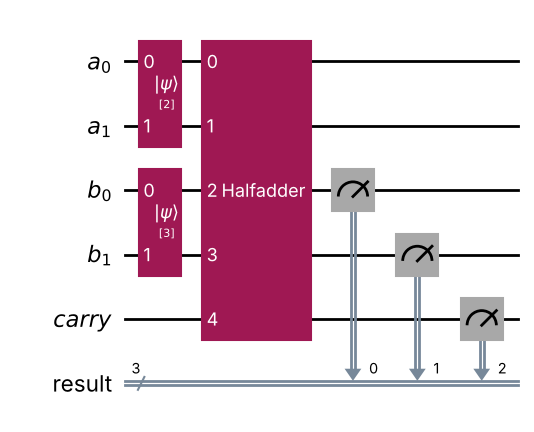

In [4]:
reg_a = QuantumRegister(num_qubits, 'a')
reg_b = QuantumRegister(num_qubits, 'b')
reg_carry = QuantumRegister(1, 'carry')
reg_res = ClassicalRegister(num_qubits + 1, 'result')

adder_circuit = QuantumCircuit(reg_a, reg_b, reg_carry, reg_res)
adder_circuit.initialize(num_1, reg_a)
adder_circuit.initialize(num_2, reg_b)
adder_circuit.append(HalfAdderGate(num_qubits), [*reg_a, *reg_b, *reg_carry])

# The sum ends up in register b plus the carry qubit
adder_circuit.measure([*reg_b, *reg_carry], reg_res)
adder_circuit.draw('mpl')

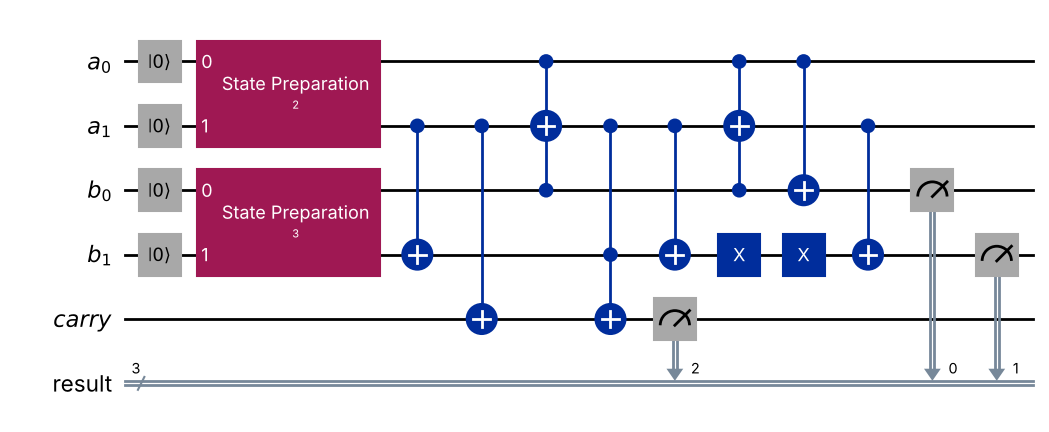

In [5]:
adder_circuit.decompose().draw('mpl')

In [6]:
counts = run(adder_circuit)
print(counts)
print(f'Most likely sum : {most_likely(counts)}')

{'101': 2000}
Most likely sum : 5


# Subtraction

An adder run **backwards** is a subtractor. `ModularAdderGate(n).inverse()` turns `b + a` into `b - a` (modulo 2^n).
If the second number is larger than the first, the answer wraps around, like two's complement.

In [7]:
num_1 = int(input('Enter First Number : '))
num_2 = int(input('Enter Second Number : '))

num_qubits = max(num_1.bit_length(), num_2.bit_length(), 1)
print(f'Each number : {num_qubits} qubits')
print(f'Result : {num_qubits} qubits (wraps around modulo 2**{num_qubits} if the answer is negative)')
print(f'Total circuit : {2 * num_qubits} qubits')

print(bin(num_1))
print(bin(num_2))
print(bin((num_1 - num_2) % 2 ** num_qubits))

Enter First Number : 20
Enter Second Number : 2
Each number : 5 qubits
Result : 5 qubits (wraps around modulo 2**5 if the answer is negative)
Total circuit : 10 qubits
0b10100
0b10
0b10010


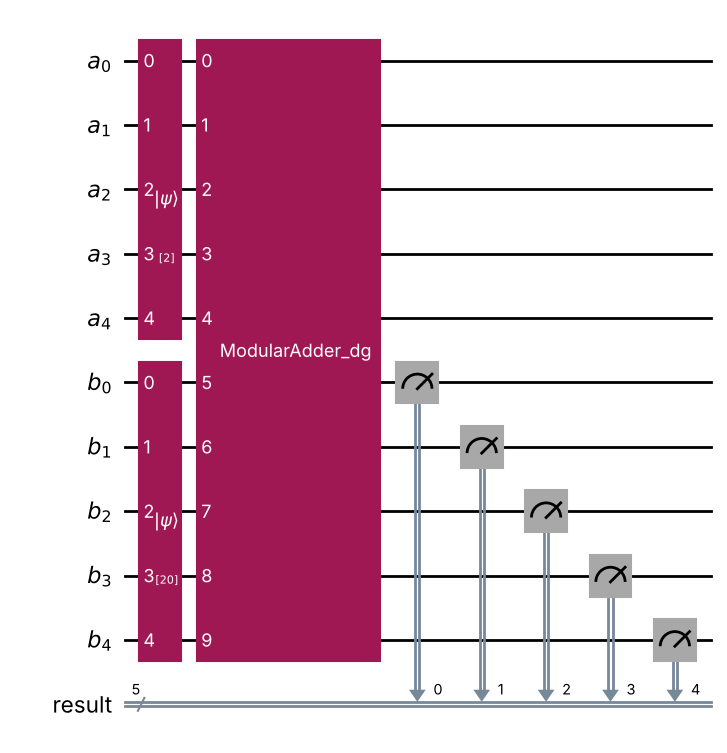

In [8]:
reg_a = QuantumRegister(num_qubits, 'a')  # the number being subtracted
reg_b = QuantumRegister(num_qubits, 'b')  # starts as the first number, ends as the difference
reg_res = ClassicalRegister(num_qubits, 'result')

subtractor_circuit = QuantumCircuit(reg_a, reg_b, reg_res)
subtractor_circuit.initialize(num_2, reg_a)
subtractor_circuit.initialize(num_1, reg_b)
subtractor_circuit.append(ModularAdderGate(num_qubits).inverse(), [*reg_a, *reg_b])
subtractor_circuit.measure(reg_b, reg_res)
subtractor_circuit.draw('mpl')

In [9]:
counts = run(subtractor_circuit)
print(counts)

difference = most_likely(counts)
if num_1 < num_2:
    difference -= 2 ** num_qubits  # read the wrapped answer as a negative number
print(f'Most likely subtraction : {difference}')

{'10010': 2000}
Most likely subtraction : 18


# Multiplication

`MultiplierGate(n, m)` multiplies two n-qubit numbers into an m-qubit result register. Two n-bit numbers need at most 2n bits for the product.

In [10]:
num_1 = int(input('Enter First Number : '))
num_2 = int(input('Enter Second Number : '))

num_qubits = max(num_1.bit_length(), num_2.bit_length(), 1)
result_qubits = 2 * num_qubits
print(f'Each number : {num_qubits} qubits')
print(f'Result : {result_qubits} qubits')
print(f'Total circuit : {4 * num_qubits} qubits')

print(bin(num_1))
print(bin(num_2))
print(bin(num_1 * num_2))

Enter First Number : 2
Enter Second Number : 3
Each number : 2 qubits
Result : 4 qubits
Total circuit : 8 qubits
0b10
0b11
0b110


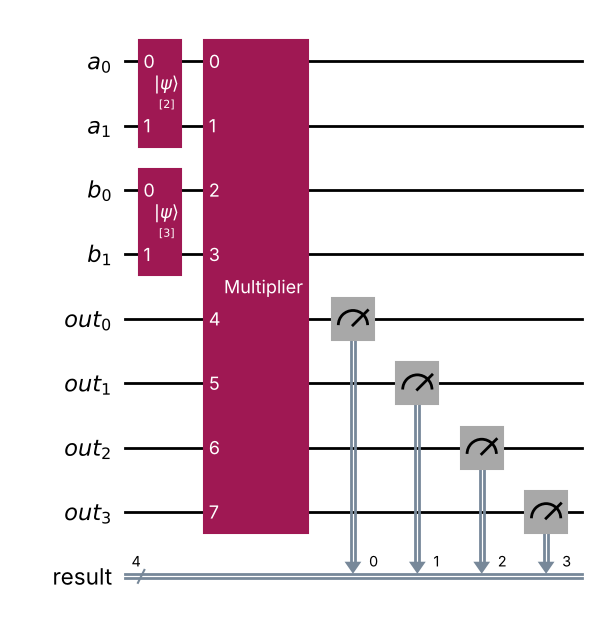

In [11]:
reg_a = QuantumRegister(num_qubits, 'a')
reg_b = QuantumRegister(num_qubits, 'b')
reg_out = QuantumRegister(result_qubits, 'out')
reg_res = ClassicalRegister(result_qubits, 'result')

multiplier_circuit = QuantumCircuit(reg_a, reg_b, reg_out, reg_res)
multiplier_circuit.initialize(num_1, reg_a)
multiplier_circuit.initialize(num_2, reg_b)
multiplier_circuit.append(MultiplierGate(num_qubits, result_qubits), [*reg_a, *reg_b, *reg_out])
multiplier_circuit.measure(reg_out, reg_res)
multiplier_circuit.draw('mpl')

In [12]:
counts = run(multiplier_circuit)
print(counts)
print(f'Most likely product : {most_likely(counts)}')

{'0110': 2000}
Most likely product : 6


# Division

Qiskit has no ready-made divider, so this one is built from the adder (restoring long division, the way you divide by hand in binary).
For each bit of the dividend, from the top down:

1. Subtract the divisor from the part of the dividend seen so far (the adder run backwards).
2. If the answer went negative (the top bit is set), the divisor did not fit. Copy that flag into the quotient qubit and add the divisor back.
3. Flip the quotient qubit, so it reads 1 when the divisor fit and 0 when it didn't.

The remainder builds up in the working register by sliding the window down one qubit each step.

In [13]:
def build_division_circuit(dividend, divisor, num_qubits):
    """Restoring long division of two numbers that each fit in num_qubits bits."""
    width = num_qubits + 1  # one extra bit so a negative answer shows up as a set top bit

    work = QuantumRegister(2 * num_qubits, 'work')    # dividend in the low qubits, remainder builds up here
    div = QuantumRegister(width, 'divisor')           # divisor, padded with a zero qubit on top
    quo = QuantumRegister(num_qubits, 'quotient')
    c_quo = ClassicalRegister(num_qubits, 'q')
    c_rem = ClassicalRegister(num_qubits, 'r')

    circuit = QuantumCircuit(work, div, quo, c_quo, c_rem)
    circuit.initialize(dividend, work[:num_qubits])
    circuit.initialize(divisor, div[:num_qubits])

    adder = ModularAdderGate(width)
    for i in reversed(range(num_qubits)):
        window = work[i:i + width]                              # the part of the dividend seen so far
        circuit.append(adder.inverse(), [*div, *window])        # window = window - divisor
        circuit.cx(window[-1], quo[i])                          # top bit set: it went negative
        circuit.append(adder.control(1), [quo[i], *div, *window])  # ...so add the divisor back
        circuit.x(quo[i])                                       # quotient bit: 1 if the divisor fit

    circuit.measure(quo, c_quo)
    circuit.measure(work[:num_qubits], c_rem)
    return circuit

In [14]:
num_1 = int(input('Enter Dividend (number to divide) : '))
num_2 = int(input('Enter Divisor (number to divide by) : '))
assert num_2 != 0, 'Cannot divide by zero'

num_qubits = max(num_1.bit_length(), num_2.bit_length(), 1)
print(f'Each number : {num_qubits} qubits')
print(f'Total circuit : {2 * num_qubits + (num_qubits + 1) + num_qubits} qubits')

print(f'{num_1} = {num_2} x {num_1 // num_2} + {num_1 % num_2}  (expected, in plain Python)')

Enter Dividend (number to divide) : 13
Enter Divisor (number to divide by) : 4
Each number : 4 qubits
Total circuit : 17 qubits
13 = 4 x 3 + 1  (expected, in plain Python)


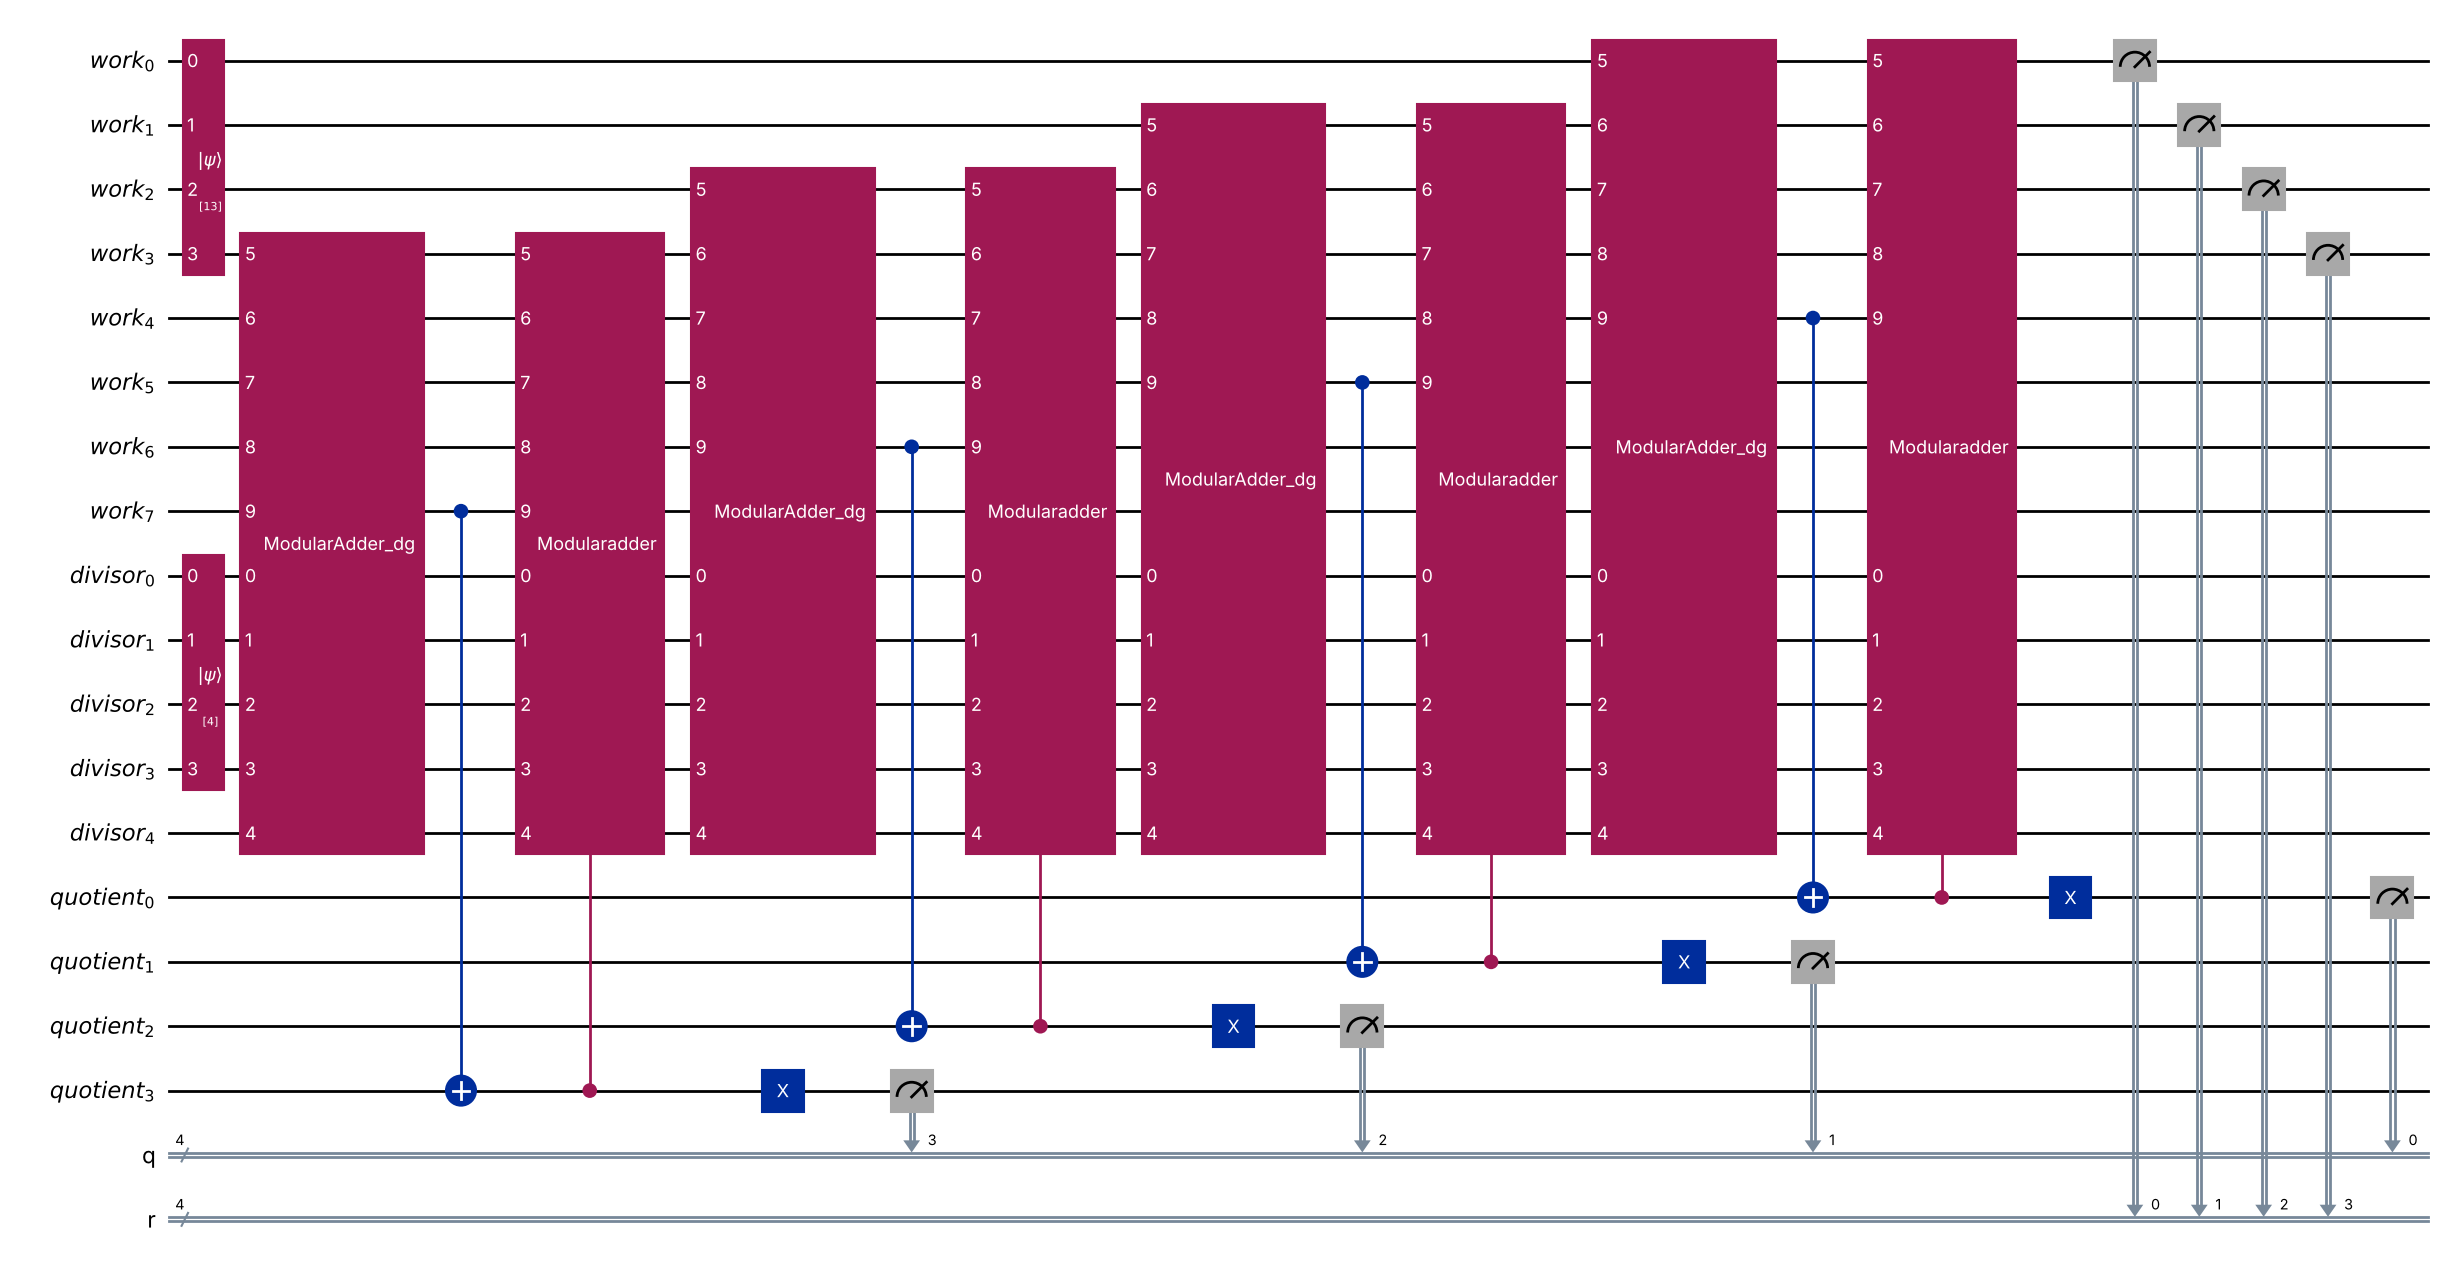

In [15]:
division_circuit = build_division_circuit(num_1, num_2, num_qubits)
division_circuit.draw('mpl', fold=-1)

In [16]:
counts = run(division_circuit)
print(counts)

# Bit strings are printed as 'remainder quotient' (last classical register first)
remainder_bits, quotient_bits = max(counts, key=counts.get).split()
print(f'Quotient : {int(quotient_bits, 2)}')
print(f'Remainder : {int(remainder_bits, 2)}')

{'0001 0011': 2000}
Quotient : 3
Remainder : 1


# Negation

Negative numbers use two's complement: flip every bit, then add one.
Here that is a row of X gates followed by the adder.

Enter a Number : 5
Each number : 4 qubits


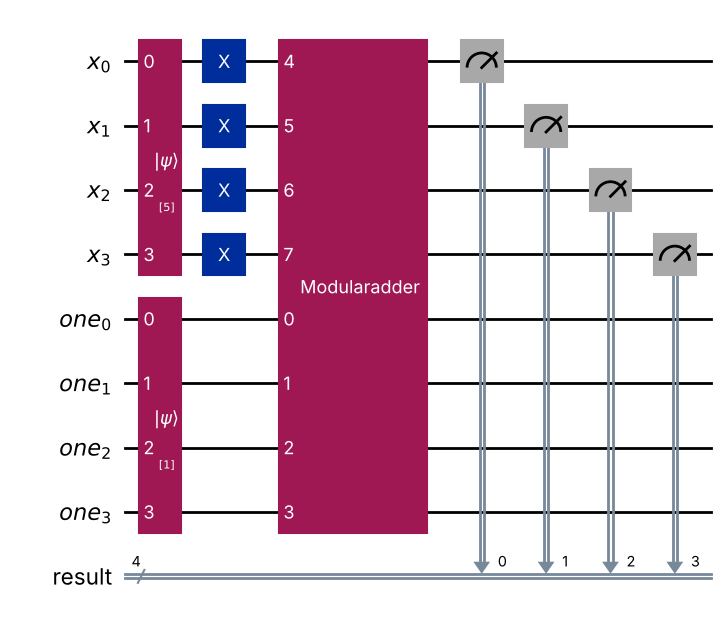

In [17]:
num = int(input('Enter a Number : '))

num_qubits = num.bit_length() + 1  # one extra bit for the sign
print(f'Each number : {num_qubits} qubits')

reg_x = QuantumRegister(num_qubits, 'x')
reg_one = QuantumRegister(num_qubits, 'one')
reg_res = ClassicalRegister(num_qubits, 'result')

negation_circuit = QuantumCircuit(reg_x, reg_one, reg_res)
negation_circuit.initialize(num, reg_x)
negation_circuit.initialize(1, reg_one)
negation_circuit.x(reg_x)                                                  # flip every bit
negation_circuit.append(ModularAdderGate(num_qubits), [*reg_one, *reg_x])  # then add one
negation_circuit.measure(reg_x, reg_res)
negation_circuit.draw('mpl')

In [18]:
counts = run(negation_circuit)
print(counts)

bits = max(counts, key=counts.get)
value = int(bits, 2)
print(f'Bits : {bits}')
print(f'Read as a signed number : {value - 2 ** num_qubits if bits[0] == "1" else value}')

{'1011': 2000}
Bits : 1011
Read as a signed number : -5


# Circuit-building experiments

Notes from exploring how circuits are put together: inspecting gates, combining circuits, turning them into reusable gates, and adding control qubits.

In [19]:
qc = QuantumCircuit(2)
qc.qubits

[<Qubit register=(2, "q"), index=0>, <Qubit register=(2, "q"), index=1>]

In [20]:
qc.x(0)
qc.data

[CircuitInstruction(operation=Instruction(name='x', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>,), clbits=())]

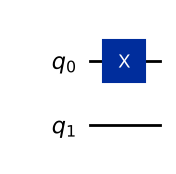

In [21]:
qc.draw('mpl')

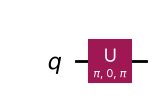

In [22]:
qc.data[0].operation.definition.draw('mpl')

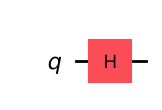

In [23]:
qc = QuantumCircuit(1)
qc.append(
    HGate(),
    [0]
)
qc.draw('mpl')

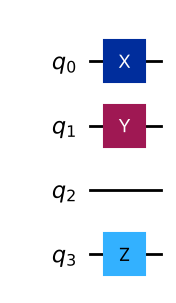

In [24]:
qc_a = QuantumCircuit(4)
qc_a.x(0)

qc_b = QuantumCircuit(2, name = 'qc_b')
qc_b.y(0)
qc_b.z(1)

ckt_combined = qc_a.compose(qc_b, qubits=[1,3])
ckt_combined.draw('mpl')

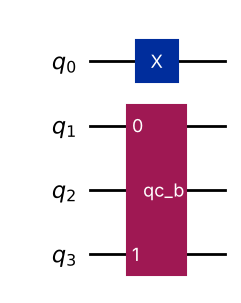

In [25]:
inst = qc_b.to_instruction()
qc_a.append(inst, [1,3])
qc_a.draw('mpl')

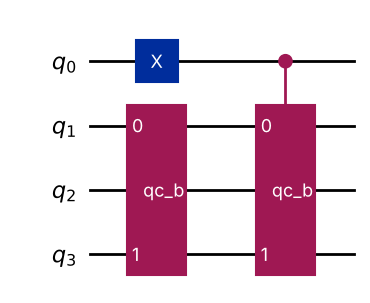

In [26]:
gate = qc_b.to_gate().control()
qc_a.append(gate, [0, 1, 3])
qc_a.draw('mpl')

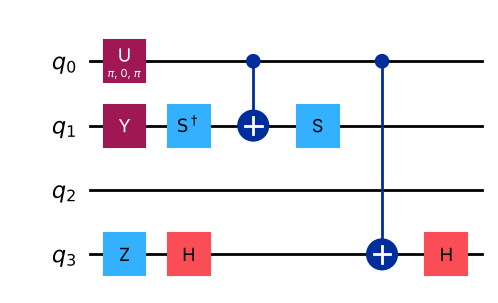

In [27]:
qc_a.decompose().draw('mpl')

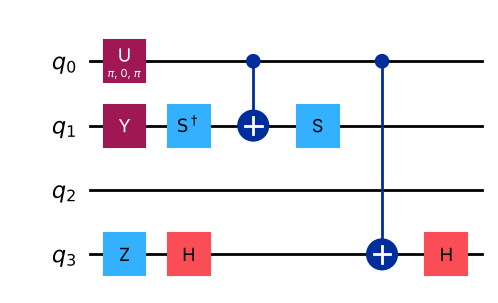

In [28]:
qc_a.decompose().draw('mpl', style='iqp')

# Functionalities

In [29]:
qubits = QuantumRegister(1, name='applyer')
clbits = ClassicalRegister(1, name='checker1')
clbits2 = ClassicalRegister(2, name='checker2')
circuit = QuantumCircuit(qubits, clbits, clbits2)

(q0,) = qubits
(c0,) = clbits
(c1) = clbits2
print(qubits)
print(clbits)
print(clbits2)

QuantumRegister(1, 'applyer')
ClassicalRegister(1, 'checker1')
ClassicalRegister(2, 'checker2')


In [30]:
print(c0)
print(c1)

<Clbit register=(1, "checker1"), index=0>
ClassicalRegister(2, 'checker2')


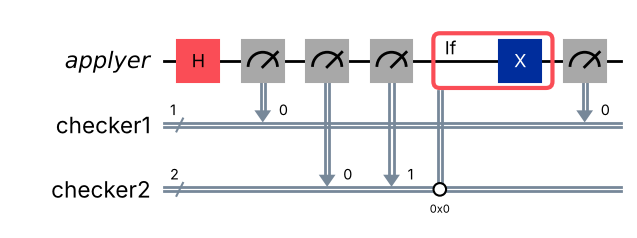

In [31]:
circuit.h(q0)
circuit.measure(q0, c0)
circuit.measure(q0, c1)

# Only one condition is tested here: if the 2-bit register c1 reads 0, flip the qubit.
# (Python's `and` can't combine two if_test blocks. Nest them to test both conditions.)
with circuit.if_test((c1, 0)):
  circuit.x(q0)

circuit.measure(q0, c0)
circuit.draw('mpl')

In [32]:
counts = run(circuit, shots=1024)
print(counts)

{'11 1': 510, '00 1': 514}


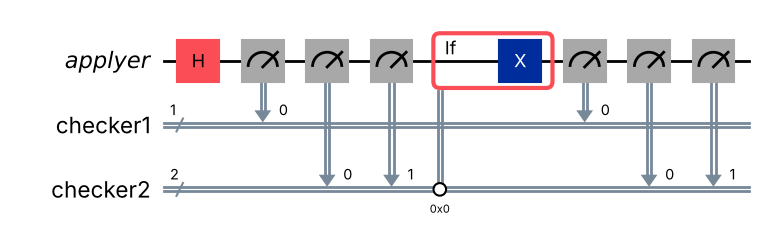

In [33]:
# Measuring into the 2-bit register again after the condition
circuit.measure(q0, c1)
circuit.draw('mpl')

# Quantum machine learning: first look

`real_amplitudes` builds a parameterized circuit (an *ansatz*) with one rotation angle per qubit per layer. The angles are what a quantum machine learning model trains.

In [34]:
num_features = 10

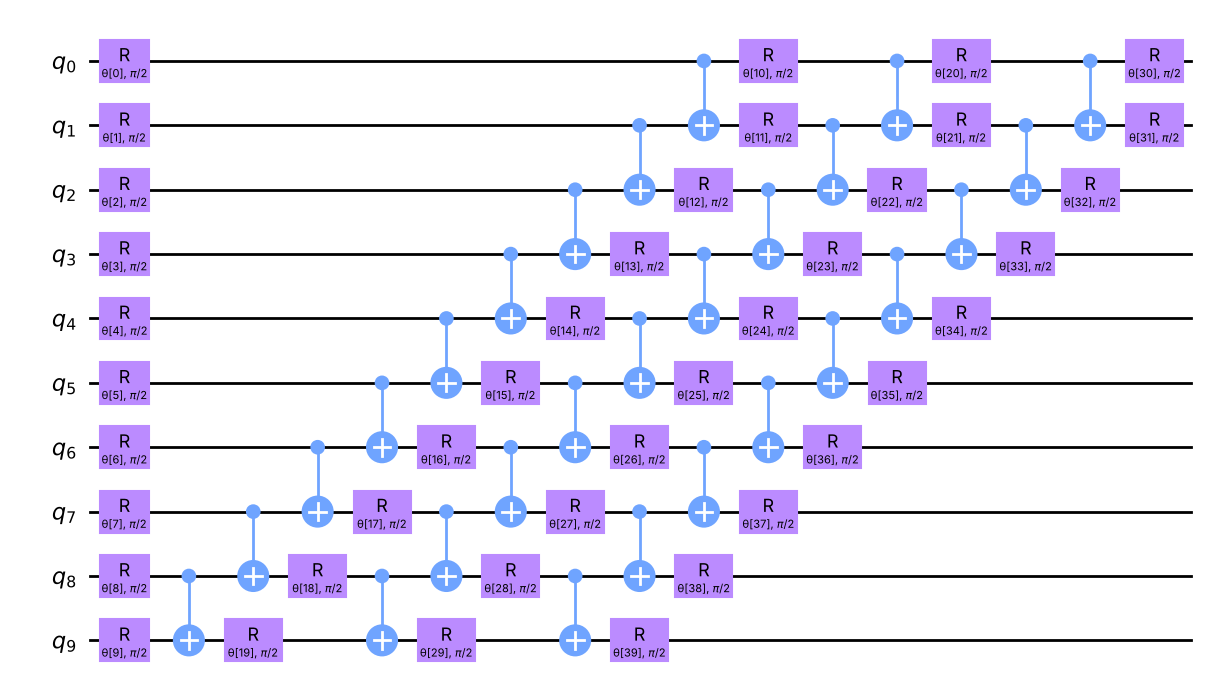

In [35]:
ansatz = real_amplitudes(num_qubits=num_features, reps=3)
ansatz.decompose().draw(output="mpl", style="clifford", fold=20)